# Case Study 18 — Cold-Start Feeds and Exploration: New-User Personalisation (Meesho) and Bandit Widget Ranking (Myntra)

**Priority:** ★★ Good to have · **Reference:** Case Study 18 — *Meesho cold start; Myntra bandit exploration* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Personalisation, Growth (new-user activation), Product (home feed), Finance
**Data:** ⚠️ **SYNTHETIC** (D-18-01). Neither company publishes logs, and the Meesho post has no numbers. This is a calibrated simulation with hidden ground truth.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs18_cold_start_exploration_bandits.ipynb`

## 0. Executive Summary for Business

«EXEC»

## 1. The Problem in Simple English

Two related problems sit behind every "feed" on a shopping app.

**Problem A: the new user.** Someone installs the app and opens it. We know almost nothing: maybe a gender and a city, maybe two or three taps. If the first feed is irrelevant they leave and do not come back ("new users rarely give second chances"). What should we show, and how fast should the feed adapt as the first clicks arrive?

**Problem B: the new item.** The home page is built from **widgets** (a "Trending" strip, a "Brands you love" strip, a deal banner). New widgets are launched and old ones retired every week. A new widget has **no click history**, so a model that only exploits history never shows it and never learns that it is good. Should we spend a little traffic **exploring**, and how much does it cost and return?

Leaders and interviewers want to know:
1. How much does each step (popularity, demographic cohorts, early behaviour, a cold/warm blend) improve the first feed, and **for whom** (zero clicks vs a few clicks)?
2. Does a **gate** that trusts demographics when history is thin and behaviour when history is rich actually learn to do that?
3. Does a bandit (LinUCB, Thompson sampling) beat a plain greedy ranker once widgets keep changing, and what does exploration **cost** in the first days?
4. Does diversity re-ranking help, and what does it cost in clicks?
5. How big would an A/B test have to be to see a **0.24%** lift like the one Myntra reported?

## 2. Reference from the Case File

### (a) What the companies did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Meesho problem | "New users rarely give second chances." Irrelevant first-session feeds drove high bounce rates; few early signals; new in-app interactions must be used in real time. Evidence level: blog by a named senior data scientist, **no numbers and no date** |
| Meesho approach | Progression: (1) DemoRec, cohort popularity by demographics; (2) ESPM, early-signal model predicting purchase probability by category from demographics plus early behaviour; (3) CWN, a cold expert (demographics) and a warm expert (interaction sequences) blended by a **gating network** driven by user-state features, with knowledge distillation applied only when the cold expert is worse. Auxiliary labels: sub_category, price_decile |
| Meesho impact | "Notable uplift" in CTR, CVR, a sharp drop in bounce rate (company claim, **no figures**) |
| Myntra problem | Rank heterogeneous homepage widgets per user when widgets are added and removed (item cold start); contextual bandit with **delayed batch feedback** |
| Myntra approach | LinUCB and linear Thompson sampling for relevance, a **forgetting factor** for batch updates, then a Determinantal Point Process (DPP) re-rank for diversity (trade-off theta 0.6 to 0.8 reported promising); baseline XGBoost |
| Myntra impact | **+0.24% homepage clicks per user** over XGBoost in an online A/B ("high statistical significance", test details not disclosed); revenue and conversion guardrails positive but unquantified (authors' claim, arXiv 2309.14046, Sep 2023) |

**Be clear about the evidence.** Public method detail is thin: Meesho gives no numbers at all, and Myntra gives one lift figure and no test design. This notebook is an **interview-standard solution on simulated data**, not a reproduction of either company's system. The Myntra +0.24% is used only as an order of magnitude.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Part A data | 40,000 new users, 24 sub-categories. Taste = global popularity + cohort effect (gender, city tier, region, age band) + individual favourites. Early clicks come from the taste with noise (35% noise when anonymous, 15% when logged in). 22% of users have zero early clicks. Three held-out future clicks per user are drawn from the true taste |
| Part A methods | (1) Popularity; (2) DemoRec cohort popularity; (3) ESPM-style multinomial logistic model on demographics plus early behaviour; (4) CWN-style gated blend of a cold and a warm expert (gate fitted on cross-fitted probabilities). Knowledge distillation is **not** reproduced |
| Part B data | 80 widgets over 60 days (30 live at the start, 3 retire and 3 launch every 4 days), 8 widget types, 8-dim user context, logistic click model with slowly drifting weights, daily batch feedback, a satiation penalty for repeating a widget type on one page |
| Part B methods | Random; greedy ridge (stand-in for Myntra's XGBoost); ε-greedy; LinUCB (alpha sensitivity); linear Thompson sampling; forgetting factor; DPP-style diversity re-rank; oracle |
| Statistics added | Cluster bootstrap CIs, paired Wilcoxon tests with Holm correction, interaction test across history buckets, paired seed-level tests for regret, sample-size and power calculations |

### (c) How the industry uses this

Cold-start feeds and exploration are used by every large Indian marketplace (Meesho, Myntra, Flipkart, Swiggy, Zepto): cohort priors for the first session, a fast switch to behaviour, and a small exploration slice for new items and creatives. It appears in interviews as "how would you recommend to a new user?" and "explore vs exploit".

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How do we make the first feed useful, and how do we launch new widgets without losing clicks or ignoring them forever? |
| Analytical | (A) Which cold-start model puts the next clicks into the feed, by amount of early history? (B) Which exploration policy gives the most clicks over 60 days with changing widgets, and at what diversity and early cost? |

**Hypotheses**
- **H1:** H0: the gated cold/warm blend has the same feed hit rate as DemoRec (paired Wilcoxon, Holm).
- **H2 (cold start):** H0: the blend's advantage over DemoRec is the same for users with 0, 1-2, 3-5 and 6+ early clicks (ANOVA interaction).
- **H3:** H0: the learned gate weight on the warm expert does not rise with early history.
- **H4:** H0: LinUCB, LinTS and ε-greedy give the same expected clicks per page as greedy (paired over 10 simulation seeds, Holm).
- **H5:** H0: DPP re-ranking leaves expected clicks unchanged while raising diversity (ILAD).

**Primary metrics:** (A) **feed hit rate**: share of a user's 3 held-out clicks that fall in the top-3 categories shown; and the noise-free **true top-3 mass**. (B) **Expected clicks per page** (5 widgets), cumulative regret against an oracle, **share of impressions to new widgets**, **ILAD** (average pairwise distance of widgets on a page).

In [1]:
import sys, warnings, importlib, os, time, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public new-user feed logs or widget click logs from Indian apps | **None.** The company posts publish no data, and Meesho's post has no numbers. Public bandit data sets (e.g. Yahoo news) are US news, not fashion widgets with churn, and have no hidden truth |
| **Decision** | Synthetic users and widgets with a hidden truth, so true feed relevance and true regret can be computed (D-18-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs18.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 18 (Meesho cold-start feeds + Myntra bandit exploration)
=============================================================================================
THIS DATA IS SYNTHETIC. Neither company publishes logs; Meesho's post has no numbers at all.

Documented context (see the reference file, Case Study 18):
  * Meesho: new users give "no second chances"; features are demographics (gender, location), early behaviour
    (clicks, interaction sequences) and user state (login, activity, lifecycle); models progress DemoRec -> ESPM -> CWN
    (cold expert + warm expert blended by a gate). Item labels: sub_category, price_decile.
  * Myntra (arXiv 2309.14046): widgets are added and removed over time (item cold start), LinUCB / linear Thompson
    sampling with delayed batch feedback and a forgetting factor, DPP diversity re-ranking; +0.24% clicks per user over XGBoost.

Part A (new-user cold start): 40,000 new users x 24 sub-categories. Taste = global popularity + cohort effect
  (gender, city tier, region, age band) + individual favourites. Early clicks come from the taste with noise (more noise
  when anonymous). Held-out future clicks are drawn from the true taste.
Part B (widget bandit): 80 widgets over 60 days (30 live at the start, 3 retire and 3 launch every 4 days), 8 widget types,
  8-dim user context, logistic click model with slowly drifting weights and a satiation penalty for repeating a widget type
  on the same page (so diversity has a true value).

Outputs: users, early_events, widgets (CSV.gz) and true_params.npz (hidden truth).
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N_U, N_C = 40_000, 24
N_W, N_TYPES, D_CTX, DAYS, SLOTS = 80, 8, 8, 60, 5
GENDER = np.array(["F", "M"]); REGION = np.array(["North", "South", "East", "West", "Central"]); AGE = np.array(["18-24", "25-34", "35-44", "45+"])


def _softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)


def generate_users(rng):
    g = (rng.random(N_U) > 0.62).astype(int); tier = rng.choice(3, N_U, p=[0.20, 0.35, 0.45]); reg = rng.integers(0, 5, N_U); age = rng.choice(4, N_U, p=[0.28, 0.40, 0.22, 0.10])
    logged = (rng.random(N_U) < 0.55).astype(int)
    pop_logit = rng.normal(0, 0.8, N_C)
    Bg, Bt, Br, Ba = rng.normal(0, 0.55, (2, N_C)), rng.normal(0, 0.45, (3, N_C)), rng.normal(0, 0.40, (5, N_C)), rng.normal(0, 0.30, (4, N_C))
    cohort = pop_logit[None, :] + Bg[g] + Bt[tier] + Br[reg] + Ba[age]
    fav = rng.integers(0, N_C, (N_U, 2)); indiv = rng.normal(0, 0.8, (N_U, N_C)); indiv[np.arange(N_U), fav[:, 0]] += 1.5; indiv[np.arange(N_U), fav[:, 1]] += 0.9
    P = _softmax(cohort + indiv)
    n_early = np.where(rng.random(N_U) < 0.22, 0, np.minimum(1 + rng.negative_binomial(1.5, 1.5 / (1.5 + 4.0), N_U), 25))
    bots = rng.choice(N_U, 80, replace=False); n_early[bots] = rng.integers(150, 300, 80)
    noise_share = np.where(logged == 1, 0.15, 0.35); gp = _softmax(pop_logit[None, :])[0]
    ev = []
    for u in range(N_U):
        n = n_early[u]
        if n == 0: continue
        q = (1 - noise_share[u]) * P[u] + noise_share[u] * gp; cats = rng.choice(N_C, n, p=q / q.sum())
        dwell = np.round(np.exp(rng.normal(2.0 + 1.0 * (P[u][cats] > 1.5 / N_C), 0.6)), 1)
        ev.extend(zip(np.full(n, u), np.arange(n), cats, dwell))
    ev = pd.DataFrame(ev, columns=["user", "seq", "sub_category", "dwell_s"])
    fut = np.array([rng.choice(N_C, 3, p=P[u]) for u in range(N_U)])
    users = pd.DataFrame({"user": np.arange(N_U), "gender": GENDER[g], "city_tier": tier + 1, "region": REGION[reg], "age_band": AGE[age], "logged_in": logged, "n_early_clicks": n_early,
                          "future_cat_1": fut[:, 0], "future_cat_2": fut[:, 1], "future_cat_3": fut[:, 2]})
    miss = rng.random(N_U) < 0.04; users.loc[miss, "region"] = None; users.loc[rng.random(N_U) < 0.04, "age_band"] = None
    ev = pd.concat([ev, ev.sample(frac=0.02, random_state=SEED)], ignore_index=True)       # duplicate-event defect
    return users, ev, dict(P=P, pop_logit=pop_logit)


def generate_bandit(rng):
    typ = rng.integers(0, N_TYPES, N_W); emb = np.eye(N_TYPES)[typ] * 1.0 + rng.normal(0, 0.25, (N_W, N_TYPES)); emb /= np.linalg.norm(emb, axis=1, keepdims=True)
    theta = rng.normal(0, 0.55, (N_W, D_CTX)); base = rng.normal(-3.7, 0.40, N_W)
    start = np.zeros(N_W, int); end = np.full(N_W, DAYS + 1)
    order = rng.permutation(N_W); live0 = order[:30]; pend = list(order[30:]); alive = list(live0); wave = 0
    for d in range(4, DAYS, 4):
        if len(pend) < 3: break
        out = rng.choice(alive, 3, replace=False)                                  # retire 3 random live widgets
        for w in out: end[w] = d; alive.remove(w)
        for _ in range(3):
            w = pend.pop(0); start[w] = d; alive.append(w)
    for w in pend: start[w] = DAYS + 5; end[w] = DAYS + 6                         # never launched
    wid = pd.DataFrame({"widget": np.arange(N_W), "widget_type": typ, "launch_day": start, "retire_day": np.minimum(end, DAYS + 1)})
    return wid, dict(typ=typ, emb=emb, theta=theta, base=base, start=start, end=end)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    users, ev, tpa = generate_users(rng); wid, tpb = generate_bandit(rng)
    return users, ev, wid, dict(**tpa, **{"b_" + k: v for k, v in tpb.items()})


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs18"), exist_ok=True)
    u, e, w, tp = generate()
    u.to_csv(os.path.join(here, "cs18", "users.csv.gz"), index=False); e.to_csv(os.path.join(here, "cs18", "early_events.csv.gz"), index=False); w.to_csv(os.path.join(here, "cs18", "widgets.csv.gz"), index=False)
    np.savez(os.path.join(here, "cs18", "true_params.npz"), **tp); print(len(u), len(e), len(w), u.n_early_clicks.describe().round(1).to_dict())

Overwriting data/generate_cs18.py


In [3]:
os.makedirs("data/cs18", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs18 as gen; importlib.reload(gen)
t0 = time.time(); users, ev, wid, TP = gen.generate(seed=SEED)
users.to_csv("data/cs18/users.csv.gz", index=False); ev.to_csv("data/cs18/early_events.csv.gz", index=False); wid.to_csv("data/cs18/widgets.csv.gz", index=False)
print(f"{len(users):,} users | {len(ev):,} early-click rows | {len(wid)} widgets | generated in {time.time() - t0:.0f}s")
users.head(4)

40,000 users | 178,471 early-click rows | 80 widgets | generated in 87s


,user,gender,city_tier,region,age_band,logged_in,n_early_clicks,future_cat_1,future_cat_2,future_cat_3
0,0,M,2,Central,45+,1,0,7,5,23
1,1,F,1,West,45+,0,6,11,18,21
2,2,M,1,North,25-34,1,0,8,8,11
3,3,M,1,North,None,1,1,4,17,11


| Parameter | Value | Basis |
|---|---|---|
| Users, categories | 40,000 new users, 24 sub-categories | Our assumption (Meesho dataset size: not disclosed) |
| Cohort effect | gender, city tier, region, age band shift category tastes | Our assumption; the post says demographics are used |
| Early behaviour | 22% zero clicks; others 1 + NB (mean 4), cap 25 | Our assumption; "few early signals" documented |
| Click noise | 35% random clicks if anonymous, 15% if logged in | Our assumption (user state is a documented gate input) |
| Widgets | 80 total, 30 live, 3 swap every 4 days, 8 types | Our assumption; widget add/remove documented |
| Click model | logit = base (≈ -3.7) + x·θ_w, θ drifts N(0, 0.02) per day | Our assumption (hidden truth) |
| Satiation | each repeated widget type on a page cuts a click probability by 12% | Our assumption (gives diversity a true value) |
| DQ issues | 2% duplicate click rows, 80 scripted users with 150-300 clicks, 4% missing region and 4% missing age | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("users: user, gender, city_tier, region, age_band", "New-user demographics (region and age may be missing)"), ("logged_in", "1 if logged in at first session (user state)"),
    ("n_early_clicks", "Number of early clicks recorded before the first feed decision"), ("future_cat_1..3", "Sub-categories of the user's next three clicks (evaluation labels)"),
    ("early_events: user, seq, sub_category, dwell_s", "Early click sequence with dwell time in seconds"), ("widgets: widget, widget_type, launch_day, retire_day", "Widget lifecycle on the home page over 60 days"),
    ("true_params.npz: P, pop_logit, b_*", "HIDDEN: true category taste per user, widget click weights, types, embeddings, schedule (digital twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs18/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"users: user, gender, city_tier, region, age_band",New-user demographics (region and age may be m...
1,logged_in,1 if logged in at first session (user state)
2,n_early_clicks,Number of early clicks recorded before the fir...
3,future_cat_1..3,Sub-categories of the user's next three clicks...
4,"early_events: user, seq, sub_category, dwell_s",Early click sequence with dwell time in seconds
5,"widgets: widget, widget_type, launch_day, reti...",Widget lifecycle on the home page over 60 days
6,"true_params.npz: P, pop_logit, b_*","HIDDEN: true category taste per user, widget c..."


## 5. Data Quality Checks

In [5]:
cnt = ev.groupby("user").size()
checks = {"duplicate early-click rows": int(ev.duplicated().sum()), "scripted users (> 100 early clicks)": int((users.n_early_clicks > 100).sum()), "missing region": int(users.region.isna().sum()), "missing age band": int(users.age_band.isna().sum())}
print(pd.Series(checks, name="rows").to_string())
ev = ev.drop_duplicates().reset_index(drop=True); bots = users.user[users.n_early_clicks > 100].values
match = (ev.groupby("user").size().reindex(users.user).fillna(0).values == users.n_early_clicks.values).mean()
users = users[~users.user.isin(bots)].reset_index(drop=True); ev = ev[~ev.user.isin(bots)]; users["region"] = users.region.fillna("unknown"); users["age_band"] = users.age_band.fillna("unknown")
print(f"\nAfter de-duplication the event count matches the user table for {match:.1%} of users (before dropping scripted users)")
print(f"Clean: {len(users):,} users | {len(ev):,} early clicks | zero early clicks: {(users.n_early_clicks == 0).mean():.1%} | anonymous: {(users.logged_in == 0).mean():.1%} | median early clicks {users.n_early_clicks.median():.0f}")

duplicate early-click rows             3499
scripted users (> 100 early clicks)      80
missing region                         1557
missing age band                       1673



After de-duplication the event count matches the user table for 100.0% of users (before dropping scripted users)
Clean: 39,920 users | 156,945 early clicks | zero early clicks: 21.6% | anonymous: 45.1% | median early clicks 3


**Observation:** «O5»

## 6. Exploratory Data Analysis

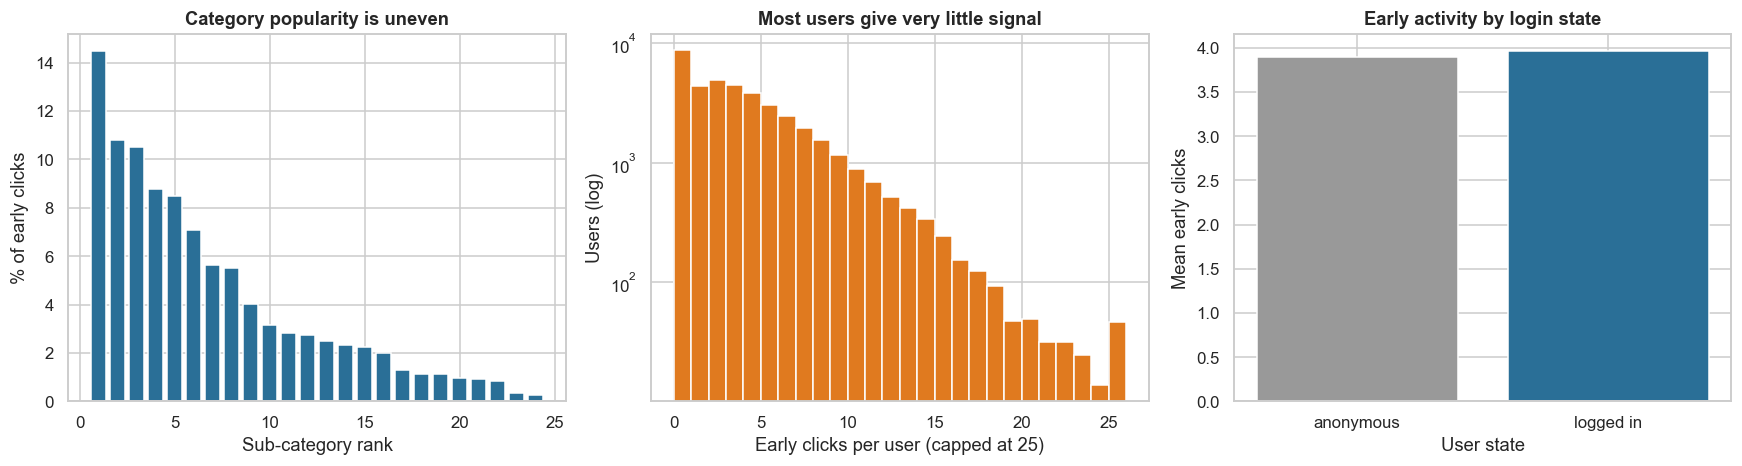

Top 3 categories = 35.8% of early clicks; users with 0 clicks 21.6%, with 1-2 23.1%, with 6+ 27.1%; mean early clicks anonymous 3.89 vs logged in 3.96


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
cs_ = np.sort(np.bincount(ev.sub_category, minlength=gen.N_C))[::-1]; axes[0].bar(np.arange(1, gen.N_C + 1), cs_ / cs_.sum() * 100, color="#2a6f97"); axes[0].set_xlabel("Sub-category rank"); axes[0].set_ylabel("% of early clicks"); axes[0].set_title("Category popularity is uneven")
axes[1].hist(users.n_early_clicks.clip(upper=25), bins=np.arange(0, 27), color="#e07a1f"); axes[1].set_yscale("log"); axes[1].set_xlabel("Early clicks per user (capped at 25)"); axes[1].set_ylabel("Users (log)"); axes[1].set_title("Most users give very little signal")
g_ = users.groupby("logged_in").n_early_clicks.mean(); axes[2].bar(["anonymous", "logged in"], g_.values, color=["#999999", "#2a6f97"]); axes[2].set_xlabel("User state"); axes[2].set_ylabel("Mean early clicks"); axes[2].set_title("Early activity by login state")
plt.tight_layout(); plt.show()
print(f"Top 3 categories = {cs_[:3].sum() / cs_.sum():.1%} of early clicks; users with 0 clicks {(users.n_early_clicks == 0).mean():.1%}, with 1-2 {users.n_early_clicks.between(1, 2).mean():.1%}, with 6+ {(users.n_early_clicks >= 6).mean():.1%}; mean early clicks anonymous {g_[0]:.2f} vs logged in {g_[1]:.2f}")

**Takeaway:** «O61»

## 7. Statistical Analysis (core section)

### Part A. The new user

### 7.1 Setup: four cold-start models and a held-out test

**Evaluation protocol:** users are split 50/50 at random into train and test. Models learn from train users' **three future clicks** (the "next-session" target) using demographics and early behaviour. On test users, each model shows its **top-3 categories**; **hit rate** = share of the user's 3 future clicks in those categories (0, 1/3, 2/3, 1). Because the truth is known, we also compute the **true top-3 mass** (the probability a future click lands in the feed) and the best possible value (oracle).

| # | Model | In one line |
|---|---|---|
| 1 | Popularity | Same top-3 categories for everybody |
| 2 | DemoRec | Top-3 categories of the user's gender × tier × region cohort (smoothed toward global with weight 20) |
| 3 | ESPM-style | One multinomial logistic model on demographics + early category shares + log history |
| 4 | CWN-style | Cold expert (demographics only) and warm expert (early behaviour only), blended by a gate g = sigmoid(w·[1, log(1+n), logged in, n = 0]) fitted on cross-fitted probabilities |

#### Code

In [7]:
NC = gen.N_C; P_all = TP["P"]; uid = users.user.values; NU = len(uid); P_true = P_all[uid]
C = np.zeros((gen.N_U, NC)); np.add.at(C, (ev.user.values, ev.sub_category.values), 1); C = C[uid]; n = C.sum(1); share = C / np.maximum(n, 1)[:, None]
demo = pd.get_dummies(users[["gender", "region", "age_band"]].assign(city_tier=users.city_tier.astype(str)), dtype=float); demo["logged_in"] = users.logged_in.values.astype(float)
Xd = demo.values; Xw = np.hstack([share, np.log1p(n)[:, None], (n == 0).astype(float)[:, None], users.logged_in.values[:, None].astype(float)]); Xe = np.hstack([Xd, Xw[:, :-1]])
fut = users[["future_cat_1", "future_cat_2", "future_cat_3"]].values
perm = RNG.permutation(NU); tr, te = np.sort(perm[:NU // 2]), np.sort(perm[NU // 2:])
def fit_lr(X, rows):
    m = LogisticRegression(max_iter=300); m.fit(np.repeat(X[rows], 3, axis=0), fut[rows].ravel()); return m
def probs(m, X):
    p = np.full((len(X), NC), 1e-6); p[:, m.classes_] = m.predict_proba(X); return p / p.sum(1, keepdims=True)
t0 = time.time()
# 1 popularity, 2 DemoRec
gshare = np.bincount(fut[tr].ravel(), minlength=NC) / fut[tr].size; P_pop = np.tile(gshare, (len(te), 1))
key = (users.gender + "|" + users.city_tier.astype(str) + "|" + users.region).values; P_demo = np.zeros((len(te), NC)); cells = {}
for k in np.unique(key[tr]):
    r = tr[key[tr] == k]; cells[k] = (np.bincount(fut[r].ravel(), minlength=NC) + 20 * gshare) / (fut[r].size + 20)
P_demo = np.array([cells.get(k, gshare) for k in key[te]])
# 3 ESPM-style, 4 cold + warm experts
P_espm = probs(fit_lr(Xe, tr), Xe[te]); m_cold = fit_lr(Xd, tr); m_warm = fit_lr(Xw, tr); Pc_te, Pw_te = probs(m_cold, Xd[te]), probs(m_warm, Xw[te])
# cross-fitted expert probabilities on train users, to fit the gate honestly
Pc_cv, Pw_cv = np.zeros((len(tr), NC)), np.zeros((len(tr), NC))
for a, b in KFold(3, shuffle=True, random_state=SEED).split(tr):
    Pc_cv[b] = probs(fit_lr(Xd, tr[a]), Xd[tr[b]]); Pw_cv[b] = probs(fit_lr(Xw, tr[a]), Xw[tr[b]])
def gate_feats(rows): return np.column_stack([np.ones(len(rows)), np.log1p(n[rows]), users.logged_in.values[rows], (n[rows] == 0).astype(float)])
Gtr = gate_feats(tr); ytr = fut[tr]
def nll(w):
    g = 1 / (1 + np.exp(-Gtr @ w)); out = 0
    for j in range(3):
        y = ytr[:, j]; out -= np.log(g * Pw_cv[np.arange(len(tr)), y] + (1 - g) * Pc_cv[np.arange(len(tr)), y] + 1e-12).mean()
    return out / 3
res_g = optimize.minimize(nll, np.zeros(4), method="BFGS"); wg = res_g.x
g_te = 1 / (1 + np.exp(-gate_feats(te) @ wg)); P_cwn = g_te[:, None] * Pw_te + (1 - g_te[:, None]) * Pc_te
print(f"Fitted in {time.time() - t0:.0f}s | train users {len(tr):,}, test users {len(te):,} | gate weights [intercept, log(1+n), logged in, n=0] = {np.round(wg, 2)} | gate NLL {res_g.fun:.4f}")

Fitted in 1929s | train users 19,960, test users 19,960 | gate weights [intercept, log(1+n), logged in, n=0] = [-2.31  0.64  0.48 -2.22] | gate NLL 2.5564


**Observation:** «O71»

### 7.2 Which model puts the next clicks in the feed? Paired tests on the same users

**(a) Why?** All models are scored on the **same test users**, so tests are paired: a **Wilcoxon signed-rank** test on each user's hit rate, a **user-level bootstrap** (500 resamples) for the confidence interval of the difference, Holm correction across the comparisons with the best model.

#### Code

In [8]:
PT = {"1 popularity": P_pop, "2 DemoRec cohort": P_demo, "3 ESPM-style": P_espm, "4 CWN-style gated blend": P_cwn}
top3 = lambda P: np.argsort(-P, axis=1)[:, :3]
FEED = {k: top3(P) for k, P in PT.items()}; FEED["oracle (true top 3)"] = top3(P_true[te])
hit = {k: np.array([np.isin(fut[te][i], f[i]).mean() for i in range(len(te))]) for k, f in FEED.items()}
mass = {k: np.take_along_axis(P_true[te], f, 1).sum(1) for k, f in FEED.items()}
def boot_ci(x, B=500):
    idx = RNG.integers(0, len(x), (B, len(x))); m = x[idx].mean(1); return np.percentile(m, 2.5), np.percentile(m, 97.5)
rows = []
for k in FEED:
    lo, hi = boot_ci(hit[k]); rows.append((k, hit[k].mean(), lo, hi, mass[k].mean()))
res = pd.DataFrame(rows, columns=["model", "feed hit rate", "CI low", "CI high", "true top-3 mass"]).set_index("model")
best = res.drop("oracle (true top 3)")["feed hit rate"].idxmax(); rows = []
for k in PT:
    if k == best: continue
    d = hit[best] - hit[k]; lo, hi = boot_ci(d); rows.append((k, d.mean(), lo, hi, stats.wilcoxon(hit[best], hit[k]).pvalue))
pt = pd.DataFrame(rows, columns=[f"vs {best}", "Δ hit rate (best − other)", "CI low", "CI high", "Wilcoxon p"]).set_index(f"vs {best}"); pt["p_holm"] = multipletests(pt["Wilcoxon p"], method="holm")[1]
print(res.round(4).to_string()); print(f"\nBest non-oracle model: {best}"); pt.round(4)

                         feed hit rate  CI low  CI high  true top-3 mass
model                                                                   
1 popularity                    0.3776  0.3730   0.3820           0.3755
2 DemoRec cohort                0.4536  0.4491   0.4578           0.4526
3 ESPM-style                    0.4755  0.4712   0.4802           0.4745
4 CWN-style gated blend         0.4698  0.4655   0.4737           0.4693
oracle (true top 3)             0.5922  0.5880   0.5966           0.5907

Best non-oracle model: 3 ESPM-style


,Δ hit rate (best − other),CI low,CI high,Wilcoxon p,p_holm
vs 3 ESPM-style,,,,,
1 popularity,0.0979,0.0930,0.1020,0.0000,0.0000
2 DemoRec cohort,0.0219,0.0191,0.0247,0.0000,0.0000
4 CWN-style gated blend,0.0057,0.0038,0.0080,0.0000,0.0000


**Observation:** «O72»

### 7.3 Cold start by amount of early history, and does the gate learn?

Users are bucketed by early clicks: 0, 1-2, 3-5, 6+. For each bucket we report hit rate, the blend's gain over DemoRec with a bootstrap CI, and the **mean gate weight on the warm expert**. An **ANOVA interaction test** asks whether the blend's per-user gain over DemoRec differs across buckets.

#### Code

In [9]:
nt = n[te]; bk = np.where(nt == 0, "0 clicks", np.where(nt <= 2, "1-2 clicks", np.where(nt <= 5, "3-5 clicks", "6+ clicks"))); order = ["0 clicks", "1-2 clicks", "3-5 clicks", "6+ clicks"]; rows = []
kb, kd, kp, ke = "4 CWN-style gated blend", "2 DemoRec cohort", "1 popularity", "3 ESPM-style"
for b_ in order:
    m = bk == b_; d = hit[kb][m] - hit[kd][m]; lo, hi = boot_ci(d)
    rows.append((b_, int(m.sum()), hit[kp][m].mean(), hit[kd][m].mean(), hit[ke][m].mean(), hit[kb][m].mean(), d.mean(), lo, hi, mass["oracle (true top 3)"][m].mean(), g_te[m].mean()))
cb = pd.DataFrame(rows, columns=["history", "users", "popularity", "DemoRec", "ESPM-style", "CWN-style", "Δ CWN − DemoRec", "CI low", "CI high", "oracle mass", "mean gate (warm weight)"]).set_index("history")
dfb = pd.DataFrame({"d": hit[kb] - hit[kd], "bucket": bk}); an = anova_lm(smf.ols("d ~ C(bucket)", data=dfb).fit())
rho_g = stats.spearmanr(np.log1p(nt), g_te)[0]
print(f"Interaction (gain over DemoRec by history bucket): F = {an['F'].iloc[0]:.1f}, p = {an['PR(>F)'].iloc[0]:.2g} | Spearman(log(1+n), gate) = {rho_g:+.2f}")
cb.round(4)

PatsyError: Error evaluating factor: TypeError: 'numpy.ndarray' object is not callable
    d ~ C(bucket)
        ^^^^^^^^^

**Observation:** «O73»

### 7.4 Early-signal quality: accuracy by clicks and the gate by login state

Anonymous users click more randomly (35% noise vs 15%), so their early clicks are weaker evidence. We plot the blend and DemoRec by exact number of early clicks, and the gate weight for anonymous vs logged-in users.

#### Code

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6)); cap = np.minimum(nt, 10)
for k, c_, ls in ((kp, "#999999", "--"), (kd, "#2a6f97", "-"), (ke, "#6a994e", "-"), (kb, "#e07a1f", "-")):
    s = pd.Series(mass[k]).groupby(cap).mean(); axes[0].plot(s.index, s.values, color=c_, ls=ls, marker="o", label=k[2:] if k != kp else "popularity")
s = pd.Series(mass["oracle (true top 3)"]).groupby(cap).mean(); axes[0].plot(s.index, s.values, color="black", ls=":", label="oracle")
axes[0].set_xlabel("Early clicks (10 = 10 or more)"); axes[0].set_ylabel("True top-3 mass of the feed"); axes[0].set_title("Feed relevance rises with early history"); axes[0].legend(fontsize=8)
for lg, c_, lab in ((0, "#999999", "anonymous"), (1, "#2a6f97", "logged in")):
    mk = users.logged_in.values[te] == lg; s = pd.Series(g_te[mk]).groupby(cap[mk]).mean(); axes[1].plot(s.index, s.values, color=c_, marker="o", label=lab)
axes[1].set_xlabel("Early clicks (10 = 10 or more)"); axes[1].set_ylabel("Gate weight on the warm expert"); axes[1].set_title("The gate hands over to behaviour as history grows"); axes[1].legend()
plt.tight_layout(); plt.show()
li = users.logged_in.values[te]; dd_ = hit[kb] - hit[kd]
for lg in (0, 1):
    mk = (li == lg) & (nt >= 3); lo, hi = boot_ci(dd_[mk]); print(f"{'logged in' if lg else 'anonymous'} users with 3+ clicks: gain of blend over DemoRec = {dd_[mk].mean():+.4f} (CI {lo:+.4f} to {hi:+.4f}), n = {mk.sum():,}, mean gate {g_te[mk].mean():.3f}")

**Takeaway:** «O74»

### Part B. The new widget: exploration with a bandit

### 7.5 Setup: a widget-ranking simulator and eleven policies

**(a) Why?** Each simulated day, 1,000 users arrive with an 8-dim context; the policy ranks the **live** widgets and shows 5. Clicks follow a hidden logistic model (weights drift slowly, repeating a widget type on one page reduces clicks by 12%). The policy learns from **daily batch feedback** only, with a linear click model per widget (LinUCB style: ridge regression with an uncertainty width). A new widget starts with zero history. Every policy sees the **same users each day** (common random numbers), and the whole run is repeated for **10 seeds**, so differences are paired.

| Policy | Rule |
|---|---|
| oracle | true click probability (upper bound on relevance) |
| random | uniform random widgets |
| greedy (ridge) | highest predicted click rate; a **stand-in** for Myntra's XGBoost baseline, not the real one |
| ε-greedy 5% | 5% of users get random widgets |
| LinUCB α | predicted click + α × uncertainty width; α ∈ {0.05, 0.1, 0.2} |
| LinTS v = 0.1 | sample each user-widget score from the posterior |
| LinUCB, γ = 0.95 | as LinUCB α=0.1 with a daily **forgetting factor** |
| + DPP θ = 0.7 | take the top 12 by score, then pick 5 by a greedy determinant (DPP) rule with relevance weight θ and widget-type similarity |

α, v, γ and θ are **fixed sensitivity settings, not tuned**.

#### Code

In [ ]:
TPB = {k[2:]: v for k, v in TP.items() if k.startswith("b_")}
W, DC, DAYS, SL = gen.N_W, gen.D_CTX, gen.DAYS, gen.SLOTS; d = DC + 1; LAM, RHO, NPD, NSEED = 1.0, 0.12, 1000, 10
sig = lambda z: 1 / (1 + np.exp(-z))
def dpp_select(q, S, k, theta):
    nn, m = q.shape; L = q[:, :, None] * q[:, None, :] * (theta * np.eye(m)[None] + (1 - theta) * S)
    d2 = np.einsum("nii->ni", L).copy(); c = np.zeros((nn, m, k)); sel = np.zeros((nn, k), int); ix = np.arange(nn)
    for t in range(k):
        j = d2.argmax(1); sel[:, t] = j; dj = np.sqrt(np.maximum(d2[ix, j], 1e-12))
        e = (L[ix, j, :] - np.einsum("nmt,nt->nm", c[:, :, :t], c[ix, j, :t])) / dj[:, None]
        c[:, :, t] = e; d2 = d2 - e ** 2; d2[ix, j] = -np.inf
    return sel
def run_bandit(name, policy, seed, alpha=0.1, gamma=1.0, eps=0.05, v=0.1, dpp=None):
    rr = np.random.default_rng([seed, 3, zlib.crc32(name.encode())]); dr = np.random.default_rng([seed, 2])
    th = TPB["theta"].copy(); A = np.tile(LAM * np.eye(d), (W, 1, 1)); b = np.zeros((W, d)); out = []
    for day in range(DAYS):
        th += dr.normal(0, 0.02, th.shape); L = np.where((TPB["start"] <= day) & (day < TPB["end"]))[0]; nL = len(L)
        X = np.hstack([np.ones((NPD, 1)), np.random.default_rng([seed, 1, day]).normal(0, 0.7, (NPD, DC))]); p = sig(TPB["base"][L][None, :] + X[:, 1:] @ th[L].T)
        if policy == "oracle": sc = p
        elif policy == "random": sc = rr.random((NPD, nL))
        else:
            Ai = np.linalg.inv(A[L]); mean = X @ np.einsum("wde,we->wd", Ai, b[L]).T; wd = np.sqrt(np.maximum(((X[None] @ Ai) * X[None]).sum(2).T, 0))
            if policy == "greedy": sc = mean
            elif policy == "eps": sc = np.where(rr.random((NPD, 1)) < eps, rr.random((NPD, nL)), mean)
            elif policy == "ucb": sc = mean + alpha * wd
            elif policy == "ts": sc = mean + v * wd * rr.normal(size=(NPD, nL))
        cand = np.argpartition(-sc, 11, axis=1)[:, :12]; cand = np.take_along_axis(cand, np.argsort(-np.take_along_axis(sc, cand, 1), 1), 1)
        if dpp is None: sh = cand[:, :SL]
        else:
            q = np.clip(np.take_along_axis(sc, cand, 1), 0.005, 1.0); E = TPB["emb"][L[cand]]; S = np.einsum("nmk,njk->nmj", E, E)
            sh = np.take_along_axis(cand, dpp_select(q, S, SL, dpp), 1)
        G = L[sh]; pt = np.take_along_axis(p, sh, 1); ty = TPB["typ"][G]; same = (ty[:, :, None] == ty[:, None, :]).sum(2) - 1
        pe = pt * np.clip(1 - RHO * same, 0.2, 1); y = (rr.random(pe.shape) < pe).astype(float)
        E = TPB["emb"][G]; cs = np.einsum("nmk,njk->nmj", E, E); ilad = (1 - cs).sum((1, 2)).mean() / (SL * (SL - 1)); new = ((TPB["start"][G] > 0) & (day - TPB["start"][G] < 7)).mean()
        out.append((pe.sum(1).mean(), ilad, new, y.sum(1).mean()))
        arms = G.ravel(); Xs = np.repeat(X, SL, axis=0); ys = y.ravel(); o = np.argsort(arms, kind="stable"); arms, Xs, ys = arms[o], Xs[o], ys[o]
        u, st = np.unique(arms, return_index=True); outer = (Xs[:, :, None] * Xs[:, None, :]).reshape(len(Xs), -1)
        dA = np.add.reduceat(outer, st, 0).reshape(-1, d, d); db = np.add.reduceat(Xs * ys[:, None], st, 0)
        A = gamma * (A - LAM * np.eye(d)) + LAM * np.eye(d); b = gamma * b; A[u] += dA; b[u] += db
    return np.array(out)
CFG = {"oracle": ("oracle", {}), "random": ("random", {}), "greedy (ridge)": ("greedy", {}), "ε-greedy 5%": ("eps", {}), "LinUCB α=0.05": ("ucb", dict(alpha=0.05)), "LinUCB α=0.1": ("ucb", dict(alpha=0.1)),
       "LinUCB α=0.2": ("ucb", dict(alpha=0.2)), "LinTS v=0.1": ("ts", dict(v=0.1)), "LinUCB α=0.1, γ=0.95": ("ucb", dict(alpha=0.1, gamma=0.95)), "greedy + DPP θ=0.7": ("greedy", dict(dpp=0.7)), "LinUCB α=0.1 + DPP θ=0.7": ("ucb", dict(alpha=0.1, dpp=0.7))}
t0 = time.time(); SIM = {k: np.array([run_bandit(k, pol, s, **kw) for s in range(NSEED)]) for k, (pol, kw) in CFG.items()}   # (seeds, days, 4)
print(f"{len(CFG)} policies × {NSEED} seeds × {DAYS} days in {time.time() - t0:.0f}s | impressions per run {NPD * SL * DAYS:,}")
orc = SIM["oracle"][:, :, 0]; rows = []
for k, a in SIM.items():
    rows.append((k, a[:, :, 0].mean(), a[:, :, 0].mean() / SL, (orc - a[:, :, 0]).sum(1).mean(), a[:, :10, 0].mean(), a[:, 40:, 0].mean(), a[:, :, 1].mean(), a[:, 4:, 2].mean()))
bs = pd.DataFrame(rows, columns=["policy", "expected clicks / page", "CTR per slot", "cumulative regret (clicks per user)", "first 10 days", "last 20 days", "ILAD", "new-widget impression share"]).set_index("policy"); bs.round(4)

**Observation:** «O75»

### 7.6 Regret over time: what does exploration cost and when does it pay back?

Cumulative regret = oracle expected clicks − policy expected clicks, summed over days, averaged over the 10 seeds (shaded band = 95% t-interval over seeds). We also plot the **share of impressions given to widgets launched in the last 7 days**.

#### Code

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8)); days = np.arange(DAYS)
for k, c_ in (("random", "#bbbbbb"), ("greedy (ridge)", "#c1121f"), ("ε-greedy 5%", "#6a994e"), ("LinUCB α=0.1", "#2a6f97"), ("LinTS v=0.1", "#e07a1f")):
    cr = np.cumsum(orc - SIM[k][:, :, 0], axis=1); m = cr.mean(0); h = stats.t.ppf(0.975, NSEED - 1) * cr.std(0, ddof=1) / np.sqrt(NSEED); axes[0].plot(days, m, color=c_, label=k); axes[0].fill_between(days, m - h, m + h, color=c_, alpha=0.2)
axes[0].set_xlabel("Day"); axes[0].set_ylabel("Cumulative regret (expected clicks per user)"); axes[0].set_title("Greedy never recovers from new widgets; exploring policies flatten"); axes[0].legend(fontsize=8)
for k, c_ in (("oracle", "black"), ("greedy (ridge)", "#c1121f"), ("ε-greedy 5%", "#6a994e"), ("LinUCB α=0.1", "#2a6f97"), ("LinTS v=0.1", "#e07a1f")):
    axes[1].plot(days[4:], SIM[k][:, 4:, 2].mean(0), color=c_, label=k)
axes[1].set_xlabel("Day"); axes[1].set_ylabel("Share of impressions to widgets launched in last 7 days"); axes[1].set_title("Who gives new widgets a chance"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
cr_g = np.cumsum(orc - SIM["greedy (ridge)"][:, :, 0], axis=1); cr_u = np.cumsum(orc - SIM["LinUCB α=0.1"][:, :, 0], axis=1)
cross = [int(np.argmax(cr_u[s] < cr_g[s])) if (cr_u[s] < cr_g[s]).any() else -1 for s in range(NSEED)]
print(f"Day LinUCB α=0.1 first has lower cumulative regret than greedy, by seed: {cross} | day-0 to day-9 expected clicks: greedy {SIM['greedy (ridge)'][:, :10, 0].mean():.4f}, LinUCB {SIM['LinUCB α=0.1'][:, :10, 0].mean():.4f}")

**Takeaway:** «O76»

### 7.7 Is the exploration gain real? Paired tests across seeds

**(a) Why?** The same users are seen by every policy in each seed, so we compare **mean expected clicks per page over 60 days** with paired t-tests across the 10 seeds and Wilcoxon signed-rank (note: with 10 seeds the smallest possible Wilcoxon p is 0.002). We test each policy against greedy and then LinUCB/LinTS against ε-greedy, Holm-corrected within each family. Each seed already averages 60,000 impressions, so the seed-to-seed spread is small.

#### Code

In [ ]:
mu = {k: a[:, :, 0].mean(1) for k, a in SIM.items()}
def paired(base, others):
    rows = []
    for k in others:
        dlt = mu[k] - mu[base]; se = dlt.std(ddof=1) / np.sqrt(NSEED); h = stats.t.ppf(0.975, NSEED - 1) * se
        rows.append((k, dlt.mean(), dlt.mean() - h, dlt.mean() + h, dlt.mean() / mu[base].mean() * 100, stats.ttest_rel(mu[k], mu[base]).pvalue, stats.wilcoxon(mu[k], mu[base]).pvalue))
    t = pd.DataFrame(rows, columns=[f"vs {base}", "Δ clicks / page", "CI low", "CI high", "relative lift %", "paired t p", "Wilcoxon p"]).set_index(f"vs {base}"); t["p_holm (t)"] = multipletests(t["paired t p"], method="holm")[1]; return t
fam1 = ["ε-greedy 5%", "LinUCB α=0.05", "LinUCB α=0.1", "LinUCB α=0.2", "LinTS v=0.1", "LinUCB α=0.1, γ=0.95"]
t1 = paired("greedy (ridge)", fam1); t2 = paired("ε-greedy 5%", ["LinUCB α=0.05", "LinUCB α=0.1", "LinUCB α=0.2", "LinTS v=0.1", "LinUCB α=0.1, γ=0.95"])
print("Family 1: against greedy"); print(t1.round(4).to_string()); print("\nFamily 2: against ε-greedy 5%"); t2.round(4)

**Observation:** «O77»

### 7.8 Diversity and the forgetting factor: the DPP trade-off

DPP re-ranking spreads widget types on the page. In this simulator repeated types are penalised in the truth, so diversity has a real value; in real data the value must be measured. We compare relevance-only vs DPP versions, and the forgetting factor, on clicks and **ILAD**.

#### Code

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.2)); pol_pts = ["greedy (ridge)", "ε-greedy 5%", "LinUCB α=0.05", "LinUCB α=0.1", "LinUCB α=0.2", "LinTS v=0.1", "LinUCB α=0.1, γ=0.95", "greedy + DPP θ=0.7", "LinUCB α=0.1 + DPP θ=0.7", "oracle"]
for k in pol_pts:
    cl = SIM[k][:, :, 0].mean(1); il = SIM[k][:, :, 1].mean(1); ax.errorbar(il.mean(), cl.mean(), yerr=1.96 * cl.std(ddof=1) / np.sqrt(NSEED), fmt="o", color="#e07a1f" if "DPP" in k else "#2a6f97"); ax.annotate(k, (il.mean(), cl.mean()), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("ILAD (average pairwise widget distance on a page)"); ax.set_ylabel("Expected clicks per page"); ax.set_title("Diversity vs clicks (orange = DPP re-rank)")
plt.tight_layout(); plt.show()
t3 = paired("LinUCB α=0.1", ["LinUCB α=0.1 + DPP θ=0.7", "LinUCB α=0.1, γ=0.95"]); t4 = paired("greedy (ridge)", ["greedy + DPP θ=0.7"])
print("DPP and forgetting vs LinUCB α=0.1"); print(t3.round(4).to_string()); print("\nDPP on greedy"); print(t4.round(4).to_string())
dil = SIM["LinUCB α=0.1 + DPP θ=0.7"][:, :, 1].mean(1) - SIM["LinUCB α=0.1"][:, :, 1].mean(1); print(f"\nILAD change from DPP on LinUCB: {dil.mean():+.4f} (paired t p = {stats.ttest_1samp(dil, 0).pvalue:.2g})")

**Takeaway:** «O78»

### 7.9 What would an A/B test need? Sample sizes and the 0.24% warning

For widget clicks we take the greedy CTR per slot as the control. For each target relative lift we compute impressions per arm (80% power, α = 0.05, two-sided, Bernoulli clicks) and **users per arm** with a design effect for 10 impressions per user and intra-user correlation 0.05. For Part A we compute new users per arm needed for activation lifts under the assumed link in section 9 (activation = 3% + 0.2 × true top-3 mass).

#### Code

In [ ]:
p0 = mu["greedy (ridge)"].mean() / SL; rows = []; deff = 1 + 9 * 0.05
for rel in (0.0024, 0.01, 0.05, 0.10, 0.20):
    p1 = p0 * (1 + rel); n_imp = int(np.ceil((1.96 + 0.84) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2)); rows.append((f"+{rel:.2%}", p0, p1, n_imp, int(n_imp * deff / 10)))
ss = pd.DataFrame(rows, columns=["relative lift", "control CTR", "treatment CTR", "impressions per arm", "users per arm (10 impr., ICC 0.05)"]).set_index("relative lift")
SLOPE0, ACT0 = 0.20, 0.03; mm = {k: mass[k].mean() for k in mass}; act_base = ACT0 + SLOPE0 * mm[kd]; rows2 = []
for k in (kp, ke, kb):
    da = SLOPE0 * (mm[k] - mm[kd]); pa = act_base; pb_ = pa + da; ok = abs(da) > 1e-6
    rows2.append((f"{k[2:]} vs DemoRec", mm[k] - mm[kd], pa, pb_, int(np.ceil((1.96 + 0.84) ** 2 * (pa * (1 - pa) + pb_ * (1 - pb_)) / da ** 2)) if ok else np.nan))
sa = pd.DataFrame(rows2, columns=["comparison", "Δ true top-3 mass", "control activation", "treatment activation", "new users per arm"]).set_index("comparison")
sd_u = (hit[kb] - hit[kd]).std(); n_hit = int(np.ceil(2 * (2.8 * sd_u / 0.01) ** 2))
print(f"Greedy CTR per slot {p0:.4f}; users per arm to detect a 0.01 absolute change in per-user hit rate (offline hit-rate sd of the difference {sd_u:.3f}): {n_hit:,}")
print(ss.round(4).to_string()); print(); sa.round(5)

**Observation:** «O79»

## 8. ML Section — what we built and what is beyond it

- **Part A is deliberately small:** multinomial logistic experts and a four-parameter gate. The gate is fitted on **cross-fitted** expert probabilities so it is not trained on probabilities the experts have already seen. Meesho's CWN uses neural towers, embeddings, auxiliary sub_category and price_decile losses and **knowledge distillation**; none of that is reproduced here.
- **Part B is a linear contextual bandit:** one ridge model per widget with an uncertainty width (LinUCB) or posterior samples (LinTS), updated in daily batches with an optional forgetting factor. Myntra's exact features, hyper-parameters and baseline are not public beyond the paper; our greedy ridge is a stand-in for their XGBoost.
- **DPP re-ranking** here is a greedy determinant selection over a kernel built from relevance and widget-type similarity, a simplification of the DPP in the paper.
- **No tuning** (per the brief): α, v, γ, θ, regularisation C and the cohort smoothing weight are fixed defaults and sensitivity settings.
- **Beyond this notebook:** two-tower networks with a learned gate, off-policy evaluation of logged bandit data (inverse propensity scoring), and per-position click models.

## 9. Business Translation — ₹ impact

Assumptions (D-18-08), all ours; neither company discloses volumes. **Part A:** 30 lakh new users a month (3.6 crore a year); first-year orders per activated user 3; order value ₹350; contribution margin 8%; **activation = 3% + slope × true top-3 mass**, slope 0.2 (base), 0.1 (worst), 0.3 (best); gain = blend minus DemoRec, with the 95% bootstrap CI as worst/best. **Part B:** 50 lakh home-page loads a day; 3% of clicks become an order; order value ₹900; margin 10%. Scenarios: worst = the **documented +0.24%** relative click lift over ε-greedy's clicks per page; base = LinTS over ε-greedy (simulated); best = LinTS over greedy (simulated).

#### Code

In [ ]:
NEWU, ORD, AOVA, MGA = 3.6e7, 3, 350, 0.08; LOADS, CVB, AOVB, MGB = 5e6 * 365, 0.03, 900, 0.10
d_m = mass[kb] - mass[kd]; lo_m, hi_m = boot_ci(d_m); dm = d_m.mean()
crA = lambda dmass, slope: NEWU * slope * dmass * ORD * AOVA * MGA / 1e7
moneyA = pd.DataFrame({"Δ top-3 mass": [lo_m, dm, hi_m], "slope": [0.1, 0.2, 0.3]}, index=["worst", "base", "best"]); moneyA["Δ activation (pp)"] = moneyA["Δ top-3 mass"] * moneyA["slope"] * 100
moneyA["₹ crore / year"] = [crA(lo_m, 0.1), crA(dm, 0.2), crA(hi_m, 0.3)]
crB = lambda dclk: LOADS * dclk * CVB * AOVB * MGB / 1e7
dts = mu["LinTS v=0.1"] - mu["ε-greedy 5%"]; dtg = mu["LinTS v=0.1"] - mu["greedy (ridge)"]
moneyB = pd.DataFrame({"Δ clicks per page": [0.0024 * mu["ε-greedy 5%"].mean(), dts.mean(), dtg.mean()], "scenario basis": ["+0.24% (documented, Myntra vs XGBoost)", "LinTS vs ε-greedy (simulated)", "LinTS vs greedy (simulated)"]}, index=["worst", "base", "best"])
moneyB["relative lift %"] = [0.24, dts.mean() / mu["ε-greedy 5%"].mean() * 100, dtg.mean() / mu["greedy (ridge)"].mean() * 100]; moneyB["₹ crore / year"] = [crB(x) for x in moneyB["Δ clicks per page"]]
print(f"Part A: blend minus DemoRec top-3 mass = {dm:.4f} (CI {lo_m:.4f} to {hi_m:.4f})"); print(moneyA.round(4).to_string()); print("\nPart B"); moneyB.round(4)

**Takeaway (business reading):** «O9»

## 10. Recommendation and Decision

«O10»

## 11. Risks, Limitations and Next Steps

- **Simulated tastes and clicks:** cohort strength, click noise, widget weights and the satiation penalty were assumed. The size of every gain depends on them; only the **direction and the method** carry over.
- **Thin public evidence:** Meesho publishes no numbers; Myntra publishes one lift. We do not know either company's baseline, scale or test design.
- **Activation link is assumed:** the rupee value of Part A rests on activation = 3% + 0.2 × top-3 mass, which is not documented. Measure the link in a live test.
- **Our greedy baseline is not XGBoost:** exploring policies look strong against a greedy learner that gives a new widget a zero score; a real baseline with priors or content features would shrink the gap.
- **Offline vs online:** logged feeds reflect past exposure. Real evaluation of bandits needs logged propensities and off-policy estimators or a live test.
- **Exploration cost:** exploration spends real impressions. Cap it (e.g. 5-10% of traffic) and protect guardrails (conversion, revenue per user).
- **Next steps:** add price_decile and sub_category auxiliary labels, a neural gate, knowledge distillation; test on real first-session data; add content features for new widgets.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Feed hit rate | share of a user's future clicks that fall in the shown top-3 categories |
| True top-3 mass | Σ over shown categories of the user's true click probability |
| Gate | g = sigmoid(w · [1, log(1+n), logged in, n = 0]); p = g × p_warm + (1 − g) × p_cold |
| LinUCB score | x·θ̂_a + α √(xᵀ A_a⁻¹ x), A_a = λI + Σ xxᵀ, θ̂_a = A_a⁻¹ b_a |
| LinTS score | x·θ̂_a + v √(xᵀ A_a⁻¹ x) · z, z ~ N(0, 1) |
| Forgetting | A ← γ (A − λI) + λI, b ← γ b each day |
| Regret | oracle expected clicks − policy expected clicks, summed over days |
| ILAD | average pairwise (1 − cosine) of widget embeddings on a page |
| Sample size | n = (z_{α/2} + z_β)² [p₀(1−p₀) + p₁(1−p₁)] / (p₁ − p₀)² per arm |

| Term | Meaning |
|---|---|
| Cold start | Too little history for a user or an item |
| Gating network | A small model that decides how much to trust each expert |
| Bandit | A policy that balances showing what looks best (exploit) and learning (explore) |
| LinUCB / LinTS | Linear bandits using an optimism bonus / posterior sampling |
| DPP | Determinantal point process: selects a relevant and diverse set |
| Regret | Clicks lost against always showing the best option |
| Common random numbers | Giving every policy the same simulated users so comparisons are paired |
| Digital twin | A simulation where the true behaviour is known |